# 25a — Modern-Scorer Replication of the Generator-History Intervention

## Why this experiment

Notebook 25 established a clean but mixed cross-scorer result:

- the frozen headline scorer `Qwen/Qwen3-0.6B-Base` strongly recovered the
  long-range effect of restricting generator self-history;
- GPT-2 and SmolLM2-360M were mostly unresolved/null.

That does **not** support a simple parameter-count story, because the successful
Qwen3 scorer is itself only 0.6B parameters.

The sharper question is therefore:

> **Does the generator-history trace generalize to newer and/or
> higher-capacity pretrained observation models, or is Qwen3-0.6B unusually
> sensitive for family-specific reasons?**

No new text is generated. We reuse the exact frozen Qwen \(n=60\) and SmolLM2
\(n=40\) full-history/restricted-history pairs.

## Predeclared modern scorer panel

Primary new scorers:

1. **Qwen3-1.7B-Base** — same scorer family as the headline model, larger;
2. **OLMo-2-0425-1B** — independent modern base-model family;
3. **Falcon3-3B-Base** — independent modern base-model family and the largest
   scorer in the primary panel.

The old panel from Notebook 25 is retained only for comparison:

- Qwen3-0.6B-Base;
- GPT-2;
- SmolLM2-360M.

This design distinguishes several outcomes:

- **Qwen1.7 + OLMo2 + Falcon3 succeed:** broad modern-scorer generalization;
- **only Qwen1.7 succeeds:** likely Qwen-family observation affinity;
- **independent modern scorers succeed but Qwen1.7 does not:** capability/family
  interaction rather than monotonic scale;
- **new scorers remain mixed/null:** strong observation-model dependence.

We do **not** relabel models as "strong" or "weak" after seeing the result.


In [1]:
from pathlib import Path
import gc
import inspect
import math

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
PROJECT_ROOT = ROOT.parent
DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

NEW_SCORERS = {
    "Qwen3-1.7B": "Qwen/Qwen3-1.7B-Base",
    "OLMo2-1B": "allenai/OLMo-2-0425-1B",
    "Falcon3-3B": "tiiuae/Falcon3-3B-Base",
}

OLD_SCORER_ORDER = ["Qwen3", "GPT2", "SmolLM2"]
NEW_SCORER_ORDER = list(NEW_SCORERS)
ALL_SCORER_ORDER = OLD_SCORER_ORDER + NEW_SCORER_ORDER

PREFIX_LEN = 384
CONTEXTS = [8, 32, 128, 256]
N_TARGETS = 8

N_BOOT = 10_000
BOOT_SEED = 20260901

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# fp16 is more broadly supported on the user's RTX GPU than bf16.
DTYPE = torch.float16 if DEVICE.type == "cuda" else torch.float32

print("ROOT:", ROOT)
print("PROJECT_ROOT:", PROJECT_ROOT)
print("device:", DEVICE)
print("dtype:", DTYPE)
print("new scorers:")
for k, v in NEW_SCORERS.items():
    print(" ", k, "->", v)


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROOT: ..
PROJECT_ROOT: /home/user/Downloads/TemporalContextResearch
device: cuda
dtype: torch.float16
new scorers:
  Qwen3-1.7B -> Qwen/Qwen3-1.7B-Base
  OLMo2-1B -> allenai/OLMo-2-0425-1B
  Falcon3-3B -> tiiuae/Falcon3-3B-Base


## 1. Reconstruct the exact frozen intervention text pairs

The Qwen confirmatory \(n=60\) set combines 40 pairs from the confirmatory
generation batch and 20 from the earlier context-access intervention batch.
SmolLM2's \(n=40\) set is fully contained in the cross-generator generation
artifact.

The paired-analysis files define the exact frozen source-ID membership.


In [2]:
Q_DIR_CANDIDATES = [
    DATA / "raid_pilot" / "context_access_confirmatory",
    PROJECT_ROOT / "data" / "raid_pilot" / "context_access_confirmatory",
    PROJECT_ROOT / "results" / "raid_pilot" / "context_access_confirmatory",
]
S_DIR_CANDIDATES = [
    DATA / "raid_pilot" / "context_access_cross_generator",
    PROJECT_ROOT / "data" / "raid_pilot" / "context_access_cross_generator",
    PROJECT_ROOT / "results" / "raid_pilot" / "context_access_cross_generator",
]

Q_DIR = next((p for p in Q_DIR_CANDIDATES if (p / "confirmatory_pairs.parquet").exists()), None)
S_DIR = next((p for p in S_DIR_CANDIDATES if (p / "cross_generator_pairs.parquet").exists()), None)

assert Q_DIR is not None, "Could not locate Qwen confirmatory intervention artifacts."
assert S_DIR is not None, "Could not locate SmolLM2 intervention artifacts."

Q_OLD_CANDIDATES = [
    PROJECT_ROOT / "results" / "raid_pilot" / "context_access_intervention" / "context_access_generations.parquet",
    PROJECT_ROOT / "data" / "raid_pilot" / "context_access_intervention" / "context_access_generations.parquet",
    DATA / "raid_pilot" / "context_access_intervention" / "context_access_generations.parquet",
]
Q_OLD_PATH = next((p for p in Q_OLD_CANDIDATES if p.exists()), None)
assert Q_OLD_PATH is not None, (
    "Could not find the earlier Qwen context_access_generations.parquet.\n"
    + "\n".join(map(str, Q_OLD_CANDIDATES))
)

print("Q_DIR:", Q_DIR)
print("Q old batch:", Q_OLD_PATH)
print("S_DIR:", S_DIR)


Q_DIR: /home/user/Downloads/TemporalContextResearch/results/raid_pilot/context_access_confirmatory
Q old batch: /home/user/Downloads/TemporalContextResearch/results/raid_pilot/context_access_intervention/context_access_generations.parquet
S_DIR: /home/user/Downloads/TemporalContextResearch/results/raid_pilot/context_access_cross_generator


In [3]:
def extract_full_vs_32(df, generator_name, allowed_ids, source_name):
    required = {"source_id", "history_cap_label", "generated_text"}
    missing = required - set(df.columns)
    assert not missing, f"{source_name}: missing {missing}"

    allowed_ids = {str(x) for x in allowed_ids}

    z = df.copy()
    z["source_id"] = z["source_id"].astype(str)
    z = z[z["source_id"].isin(allowed_ids)].copy()
    z["_cond"] = z["history_cap_label"].astype(str).str.strip().str.lower()
    z = z[z["_cond"].isin({"full", "32"})].copy()

    conflicts = (
        z.groupby(["source_id", "_cond"])["generated_text"]
        .nunique()
        .reset_index(name="n_unique_texts")
    )
    conflicts = conflicts[conflicts["n_unique_texts"] > 1]
    if len(conflicts):
        display(conflicts)
        raise RuntimeError(f"{source_name}: conflicting duplicate generations.")

    z = z.drop_duplicates(["source_id", "_cond", "generated_text"])

    counts = z.groupby(["source_id", "_cond"]).size().unstack(fill_value=0)
    full_counts = counts["full"] if "full" in counts else pd.Series(0, index=counts.index)
    cap_counts = counts["32"] if "32" in counts else pd.Series(0, index=counts.index)
    good_ids = counts.index[(full_counts == 1) & (cap_counts == 1)]
    z = z[z["source_id"].isin(good_ids)].copy()

    wide = (
        z.pivot(index="source_id", columns="_cond", values="generated_text")
        .reset_index()
        .rename(columns={
            "source_id": "pair_id",
            "full": "full_text",
            "32": "restricted_text",
        })
    )
    wide["generator"] = generator_name
    wide["source_path"] = source_name
    return wide[["pair_id","generator","full_text","restricted_text","source_path"]]

# Qwen n=60.
qp = pd.read_parquet(Q_DIR / "confirmatory_pairs.parquet")
q_target_ids = set(qp["source_id"].astype(str))
q_raw = pd.concat([
    pd.read_parquet(Q_DIR / "confirmatory_generations.parquet"),
    pd.read_parquet(Q_OLD_PATH),
], ignore_index=True)

q_pairs = extract_full_vs_32(
    q_raw,
    "Qwen2.5-1.5B-Instruct",
    q_target_ids,
    "confirmatory_generations + earlier context_access_generations",
)
assert len(q_pairs) == 60
assert set(q_pairs["pair_id"]) == q_target_ids

# Smol n=40.
sp = pd.read_parquet(S_DIR / "cross_generator_pairs.parquet")
s_target_ids = set(sp["source_id"].astype(str))
s_raw = pd.read_parquet(S_DIR / "cross_generator_generations.parquet")

s_pairs = extract_full_vs_32(
    s_raw,
    "SmolLM2",
    s_target_ids,
    "cross_generator_generations",
)
assert len(s_pairs) == 40
assert set(s_pairs["pair_id"]) == s_target_ids

pairs = pd.concat([q_pairs, s_pairs], ignore_index=True)
assert not pairs[["generator","pair_id"]].duplicated().any()

display(
    pairs.groupby("generator")
    .agg(n_pairs=("pair_id","size"))
    .reset_index()
)


,generator,n_pairs
0,Qwen2.5-1.5B-Instruct,60
1,SmolLM2,40


## 2. Frozen context-utility measurement

For every scorer independently:

- tokenize the completed text with that scorer's tokenizer;
- retain its first 384 tokens;
- require both texts in a pair to be eligible;
- use the same eight deterministic target positions
  \(\operatorname{linspace}(256,383,8)\);
- compute \(L_8,L_{32},L_{128},L_{256}\);
- derive \(U(k)=L_8-L_k\).

This intentionally matches Notebook 25. We are changing the **observation
model**, not the measurement definition.


In [4]:
TARGET_POSITIONS = np.unique(
    np.linspace(
        max(CONTEXTS),
        PREFIX_LEN - 1,
        N_TARGETS,
        dtype=int,
    )
)
assert len(TARGET_POSITIONS) == N_TARGETS
print("target positions:", TARGET_POSITIONS)

def supports_logits_to_keep(model):
    try:
        return "logits_to_keep" in inspect.signature(model.forward).parameters
    except Exception:
        return False

def load_scorer(model_name):
    tok = AutoTokenizer.from_pretrained(model_name, use_fast=True)
    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token

    kwargs = dict(low_cpu_mem_usage=True)
    try:
        model = AutoModelForCausalLM.from_pretrained(
            model_name,
            dtype=DTYPE if DEVICE.type == "cuda" else torch.float32,
            **kwargs,
        )
    except TypeError:
        model = AutoModelForCausalLM.from_pretrained(
            model_name,
            torch_dtype=DTYPE if DEVICE.type == "cuda" else torch.float32,
            **kwargs,
        )

    model.to(DEVICE).eval()
    return tok, model

def encode_prefix(tok, text):
    return tok(
        str(text),
        add_special_tokens=False,
        truncation=False,
    )["input_ids"][:PREFIX_LEN]

@torch.inference_mode()
def score_ids(model, ids):
    assert len(ids) == PREFIX_LEN

    losses = {k: [] for k in CONTEXTS}

    # Falcon3-3B is close to the VRAM limit.
    # Score target positions one at a time and keep only last-position logits.
    for k in CONTEXTS:
        for t in TARGET_POSITIONS:
            context = torch.tensor(
                ids[t-k:t],
                dtype=torch.long,
                device=DEVICE,
            ).unsqueeze(0)

            target = torch.tensor(
                [int(ids[t])],
                dtype=torch.long,
                device=DEVICE,
            )

            # Current Llama/Falcon implementations support logits_to_keep.
            # Fall back cleanly for an older/other model implementation.
            try:
                out = model(
                    input_ids=context,
                    use_cache=False,
                    logits_to_keep=1,
                )
            except TypeError:
                out = model(
                    input_ids=context,
                    use_cache=False,
                )

            logits = out.logits[:, -1, :].float()
            logp = torch.log_softmax(logits, dim=-1)
            nll = -logp.gather(1, target[:, None]).squeeze()

            losses[k].append(float(nll.cpu()))

            del context, target, out, logits, logp, nll

        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    result = {
        f"L_{k}": float(np.mean(losses[k]))
        for k in CONTEXTS
    }

    for k in [32, 128, 256]:
        result[f"U_{k}"] = result["L_8"] - result[f"L_{k}"]

    return result

target positions: [256 274 292 310 328 346 364 383]


## 3. Score only the new modern panel

Each model is loaded, scored, checkpointed, and freed before the next model is
loaded. This is intentional for an 8 GB GPU.

If a scorer-specific checkpoint already exists, it is reused rather than
recomputed.


In [5]:
NEW_SCORE_DIR = RESULTS / "context_intervention_modern_scorers"
NEW_SCORE_DIR.mkdir(parents=True, exist_ok=True)

new_frames = []

for scorer_name, model_name in NEW_SCORERS.items():
    checkpoint = NEW_SCORE_DIR / f"{scorer_name}.parquet"

    if checkpoint.exists():
        print(f"\n{scorer_name}: reusing {checkpoint}")
        frame = pd.read_parquet(checkpoint)
        new_frames.append(frame)
        continue

    print(f"\n{'='*72}")
    print(f"SCORER: {scorer_name} ({model_name})")
    print(f"{'='*72}")

    try:
        tok, model = load_scorer(model_name)
    except RuntimeError as e:
        msg = str(e).lower()
        if "out of memory" in msg:
            raise RuntimeError(
                f"{scorer_name} did not fit in GPU memory. "
                "Restart the kernel to clear CUDA state, then run this scorer alone. "
                "Do not quantize it for the primary comparison because that would "
                "change the observation model."
            ) from e
        raise

    rows = []

    for r in tqdm(
        pairs.itertuples(index=False),
        total=len(pairs),
        desc=scorer_name,
    ):
        full_ids = encode_prefix(tok, r.full_text)
        rest_ids = encode_prefix(tok, r.restricted_text)

        eligible = (
            len(full_ids) == PREFIX_LEN
            and len(rest_ids) == PREFIX_LEN
        )

        row = {
            "pair_id": str(r.pair_id),
            "generator": r.generator,
            "scorer": scorer_name,
            "scorer_checkpoint": model_name,
            "eligible": bool(eligible),
            "full_n_tokens_capped": len(full_ids),
            "restricted_n_tokens_capped": len(rest_ids),
        }

        if eligible:
            fs = score_ids(model, full_ids)
            rs = score_ids(model, rest_ids)

            for k in CONTEXTS:
                row[f"full_L_{k}"] = fs[f"L_{k}"]
                row[f"restricted_L_{k}"] = rs[f"L_{k}"]

            for k in [32,128,256]:
                row[f"full_U_{k}"] = fs[f"U_{k}"]
                row[f"restricted_U_{k}"] = rs[f"U_{k}"]
                row[f"delta_U_{k}"] = rs[f"U_{k}"] - fs[f"U_{k}"]

            row["delta_U_long"] = 0.5 * (
                row["delta_U_128"] + row["delta_U_256"]
            )

        rows.append(row)

    frame = pd.DataFrame(rows)
    frame.to_parquet(checkpoint, index=False)
    new_frames.append(frame)

    print("\nEligibility:")
    display(
        frame.groupby("generator")["eligible"]
        .agg(["sum","count"])
        .rename(columns={"sum":"eligible_pairs","count":"total_pairs"})
    )

    del model, tok
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

new_scores = pd.concat(new_frames, ignore_index=True)
NEW_ALL_PATH = RESULTS / "context_intervention_modern_scorer_scores.parquet"
new_scores.to_parquet(NEW_ALL_PATH, index=False)

print("saved:", NEW_ALL_PATH)



Qwen3-1.7B: reusing ../results/context_intervention_modern_scorers/Qwen3-1.7B.parquet

OLMo2-1B: reusing ../results/context_intervention_modern_scorers/OLMo2-1B.parquet

SCORER: Falcon3-3B (tiiuae/Falcon3-3B-Base)


Falcon3-3B: 100%|█████████████████████████████████████████████████████████████████████████████████████| 100/100 [05:15<00:00,  3.16s/it]


Eligibility:


,eligible_pairs,total_pairs
generator,,
Qwen2.5-1.5B-Instruct,59,60
SmolLM2,40,40


saved: ../results/context_intervention_modern_scorer_scores.parquet


## 4. Merge with the already-frozen Notebook 25 scorer panel

This cell requires the Notebook 25 score file:

`results/context_intervention_cross_scorer_scores.parquet`

We do **not** rescore GPT-2, SmolLM2-360M, or Qwen3-0.6B.


In [6]:
OLD_PATH = RESULTS / "context_intervention_cross_scorer_scores.parquet"
assert OLD_PATH.exists(), (
    f"Missing {OLD_PATH}. Run Notebook 25 first; its old-scorer outputs are "
    "part of this comparison."
)

old_scores = pd.read_parquet(OLD_PATH).copy()
scores = pd.concat([old_scores, new_scores], ignore_index=True)

assert not scores[["generator","pair_id","scorer"]].duplicated().any()

print("scorers:", sorted(scores["scorer"].unique()))
display(
    scores.groupby(["scorer","generator"])["eligible"]
    .agg(["sum","count"])
    .rename(columns={"sum":"eligible_pairs","count":"total_pairs"})
    .reset_index()
)


scorers: ['Falcon3-3B', 'GPT2', 'OLMo2-1B', 'Qwen3', 'Qwen3-1.7B', 'SmolLM2']


,scorer,generator,eligible_pairs,total_pairs
0,Falcon3-3B,Qwen2.5-1.5B-Instruct,59,60
1,Falcon3-3B,SmolLM2,40,40
2,GPT2,Qwen2.5-1.5B-Instruct,58,60
3,GPT2,SmolLM2,35,40
4,OLMo2-1B,Qwen2.5-1.5B-Instruct,60,60
5,OLMo2-1B,SmolLM2,37,40
6,Qwen3,Qwen2.5-1.5B-Instruct,60,60
7,Qwen3,SmolLM2,40,40
8,Qwen3-1.7B,Qwen2.5-1.5B-Instruct,60,60
9,Qwen3-1.7B,SmolLM2,40,40


## 5. Paired bootstrap estimates

For each generator/scorer:

\[
\Delta U_{\mathrm{long}}
=
\frac{\Delta U(128)+\Delta U(256)}{2}.
\]

The main evidence is the sign and confidence interval of this paired treatment
effect. We do not treat the six scorer cells as independent replications.


In [7]:
def bootstrap_mean_ci(values, n_boot=N_BOOT, seed=BOOT_SEED):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    if len(x) == 0:
        return np.nan, np.nan, np.nan

    rng = np.random.default_rng(seed)
    n = len(x)
    boot = np.empty(n_boot, dtype=float)
    for b in range(n_boot):
        idx = rng.integers(0, n, size=n)
        boot[b] = x[idx].mean()

    return (
        float(x.mean()),
        float(np.quantile(boot, .025)),
        float(np.quantile(boot, .975)),
    )

metrics = ["delta_U_32","delta_U_128","delta_U_256","delta_U_long"]
summary_rows = []

for (gen, scorer), z in (
    scores[scores["eligible"]]
    .groupby(["generator","scorer"], sort=False)
):
    for metric in metrics:
        mean, lo, hi = bootstrap_mean_ci(z[metric].to_numpy())
        summary_rows.append({
            "generator": gen,
            "scorer": scorer,
            "metric": metric,
            "n": len(z),
            "mean": mean,
            "ci_low": lo,
            "ci_high": hi,
            "direction_negative": mean < 0,
            "ci_excludes_zero_negative": hi < 0,
        })

summary = pd.DataFrame(summary_rows)

long_summary = (
    summary[summary["metric"] == "delta_U_long"]
    .copy()
)

long_summary["scorer"] = pd.Categorical(
    long_summary["scorer"],
    categories=ALL_SCORER_ORDER,
    ordered=True,
)

display(
    long_summary
    .sort_values(["generator","scorer"])
    .reset_index(drop=True)
)


,generator,scorer,metric,n,mean,ci_low,ci_high,direction_negative,ci_excludes_zero_negative
0,Qwen2.5-1.5B-Instruct,Qwen3,delta_U_long,60,-0.406647,-0.735182,-0.083587,True,True
1,Qwen2.5-1.5B-Instruct,GPT2,delta_U_long,58,-0.009853,-0.340051,0.297218,True,False
2,Qwen2.5-1.5B-Instruct,SmolLM2,delta_U_long,60,-0.231102,-0.549078,0.087153,True,False
3,Qwen2.5-1.5B-Instruct,Qwen3-1.7B,delta_U_long,60,-0.424938,-0.741800,-0.103209,True,True
4,Qwen2.5-1.5B-Instruct,OLMo2-1B,delta_U_long,60,-0.346094,-0.690940,0.007173,True,False
5,Qwen2.5-1.5B-Instruct,Falcon3-3B,delta_U_long,59,-0.016655,-0.353712,0.321341,True,False
6,SmolLM2,Qwen3,delta_U_long,40,-0.535041,-0.857431,-0.215451,True,True
7,SmolLM2,GPT2,delta_U_long,35,0.053956,-0.369613,0.486622,False,False
8,SmolLM2,SmolLM2,delta_U_long,40,-0.007843,-0.314959,0.283605,True,False
9,SmolLM2,Qwen3-1.7B,delta_U_long,40,-0.589252,-0.890384,-0.303151,True,True


## 6. Predeclared interpretation table

For each new scorer we classify only whether its long-range effect is:

- `resolved_negative`: point estimate \(<0\) and 95% CI entirely \(<0\);
- `negative_unresolved`: point estimate \(<0\), CI crosses zero;
- `nonnegative`: point estimate \(\ge0\).

This classification was defined before viewing the new scorers.


In [8]:
def classify(row):
    if row["mean"] < 0 and row["ci_high"] < 0:
        return "resolved_negative"
    if row["mean"] < 0:
        return "negative_unresolved"
    return "nonnegative"

class_df = long_summary.copy()
class_df["classification"] = class_df.apply(classify, axis=1)

display(
    class_df[
        ["generator","scorer","n","mean","ci_low","ci_high","classification"]
    ].sort_values(["generator","scorer"])
)

new_long = class_df[class_df["scorer"].astype(str).isin(NEW_SCORER_ORDER)].copy()

print("\nNEW PANEL ONLY")
display(
    new_long[
        ["generator","scorer","n","mean","ci_low","ci_high","classification"]
    ].sort_values(["generator","scorer"])
)

print(
    "\nResolved negative new-panel cells:",
    int((new_long["classification"] == "resolved_negative").sum()),
    "/",
    len(new_long),
)
print(
    "Negative point estimates in new panel:",
    int((new_long["mean"] < 0).sum()),
    "/",
    len(new_long),
)


,generator,scorer,n,mean,ci_low,ci_high,classification
3,Qwen2.5-1.5B-Instruct,Qwen3,60,-0.406647,-0.735182,-0.083587,resolved_negative
11,Qwen2.5-1.5B-Instruct,GPT2,58,-0.009853,-0.340051,0.297218,negative_unresolved
19,Qwen2.5-1.5B-Instruct,SmolLM2,60,-0.231102,-0.549078,0.087153,negative_unresolved
27,Qwen2.5-1.5B-Instruct,Qwen3-1.7B,60,-0.424938,-0.741800,-0.103209,resolved_negative
35,Qwen2.5-1.5B-Instruct,OLMo2-1B,60,-0.346094,-0.690940,0.007173,negative_unresolved
43,Qwen2.5-1.5B-Instruct,Falcon3-3B,59,-0.016655,-0.353712,0.321341,negative_unresolved
7,SmolLM2,Qwen3,40,-0.535041,-0.857431,-0.215451,resolved_negative
15,SmolLM2,GPT2,35,0.053956,-0.369613,0.486622,nonnegative
23,SmolLM2,SmolLM2,40,-0.007843,-0.314959,0.283605,negative_unresolved
31,SmolLM2,Qwen3-1.7B,40,-0.589252,-0.890384,-0.303151,resolved_negative



NEW PANEL ONLY


,generator,scorer,n,mean,ci_low,ci_high,classification
27,Qwen2.5-1.5B-Instruct,Qwen3-1.7B,60,-0.424938,-0.741800,-0.103209,resolved_negative
35,Qwen2.5-1.5B-Instruct,OLMo2-1B,60,-0.346094,-0.690940,0.007173,negative_unresolved
43,Qwen2.5-1.5B-Instruct,Falcon3-3B,59,-0.016655,-0.353712,0.321341,negative_unresolved
31,SmolLM2,Qwen3-1.7B,40,-0.589252,-0.890384,-0.303151,resolved_negative
39,SmolLM2,OLMo2-1B,37,-0.037376,-0.387958,0.321245,negative_unresolved
47,SmolLM2,Falcon3-3B,40,-0.355014,-0.691668,-0.020995,resolved_negative



Resolved negative new-panel cells: 3 / 6
Negative point estimates in new panel: 6 / 6


## 7. Common-eligible sensitivity

Within each generator, require a pair to be eligible under **all six scorers**.
This can be conservative because tokenizers differ, but it removes pair-set
composition as an explanation for cross-scorer differences.


In [9]:
elig = (
    scores.pivot_table(
        index=["generator","pair_id"],
        columns="scorer",
        values="eligible",
        aggfunc="first",
    )
    .fillna(False)
)

for scorer in ALL_SCORER_ORDER:
    if scorer not in elig.columns:
        elig[scorer] = False

elig["common_eligible"] = elig[ALL_SCORER_ORDER].all(axis=1)

common_keys = (
    elig[elig["common_eligible"]]
    .reset_index()[["generator","pair_id"]]
)

display(
    common_keys.groupby("generator")["pair_id"]
    .nunique()
    .rename("common_pairs")
    .reset_index()
)

common = scores.merge(
    common_keys.assign(common_eligible=True),
    on=["generator","pair_id"],
    how="left",
)
common = common[common["common_eligible"].fillna(False)].copy()

common_rows = []
for (gen, scorer), z in common.groupby(["generator","scorer"], sort=False):
    mean, lo, hi = bootstrap_mean_ci(z["delta_U_long"].to_numpy())
    common_rows.append({
        "generator": gen,
        "scorer": scorer,
        "n": len(z),
        "mean": mean,
        "ci_low": lo,
        "ci_high": hi,
    })

common_summary = pd.DataFrame(common_rows)
common_summary["scorer"] = pd.Categorical(
    common_summary["scorer"],
    categories=ALL_SCORER_ORDER,
    ordered=True,
)

display(
    common_summary
    .sort_values(["generator","scorer"])
    .reset_index(drop=True)
)


,generator,common_pairs
0,Qwen2.5-1.5B-Instruct,57
1,SmolLM2,33


,generator,scorer,n,mean,ci_low,ci_high
0,Qwen2.5-1.5B-Instruct,Qwen3,57,-0.372798,-0.711492,-0.041537
1,Qwen2.5-1.5B-Instruct,GPT2,57,-0.010025,-0.343446,0.302279
2,Qwen2.5-1.5B-Instruct,SmolLM2,57,-0.258696,-0.592790,0.068571
3,Qwen2.5-1.5B-Instruct,Qwen3-1.7B,57,-0.400397,-0.731887,-0.072201
4,Qwen2.5-1.5B-Instruct,OLMo2-1B,57,-0.339822,-0.714434,0.034106
5,Qwen2.5-1.5B-Instruct,Falcon3-3B,57,-0.018399,-0.356739,0.326421
6,SmolLM2,Qwen3,33,-0.501245,-0.860067,-0.135132
7,SmolLM2,GPT2,33,0.091843,-0.360006,0.547067
8,SmolLM2,SmolLM2,33,0.077825,-0.269300,0.410660
9,SmolLM2,Qwen3-1.7B,33,-0.568764,-0.925034,-0.231883


## 8. Does the Qwen-family scale-up replicate?

This is the cleanest within-family check:

\[
\text{Qwen3-0.6B-Base}
\longrightarrow
\text{Qwen3-1.7B-Base}.
\]

If both source-generator interventions remain strongly negative under
Qwen3-1.7B, the headline result is at least robust to scorer scale **within the
Qwen3 family**.

That is weaker than cross-family generalization, but scientifically useful.


In [10]:
qwen_family = long_summary[
    long_summary["scorer"].astype(str).isin(["Qwen3","Qwen3-1.7B"])
].copy()

display(
    qwen_family[
        ["generator","scorer","n","mean","ci_low","ci_high"]
    ].sort_values(["generator","scorer"])
)


,generator,scorer,n,mean,ci_low,ci_high
3,Qwen2.5-1.5B-Instruct,Qwen3,60,-0.406647,-0.735182,-0.083587
27,Qwen2.5-1.5B-Instruct,Qwen3-1.7B,60,-0.424938,-0.741800,-0.103209
7,SmolLM2,Qwen3,40,-0.535041,-0.857431,-0.215451
31,SmolLM2,Qwen3-1.7B,40,-0.589252,-0.890384,-0.303151


## 9. Cross-family modern-scorer criterion

We predeclare a conservative qualitative criterion for claiming
"modern-scorer generalization":

> For **each source generator**, at least two of the three new scorers have
> negative long-range point estimates, and at least one independent-family new
> scorer (OLMo2 or Falcon3) has a 95% CI entirely below zero.

This criterion is intentionally descriptive rather than a new omnibus
\(p\)-value, because scorer results share the same paired texts and are not
independent experiments.


In [11]:
criterion_rows = []

for gen, z in new_long.groupby("generator"):
    n_negative = int((z["mean"] < 0).sum())

    independent = z[
        z["scorer"].astype(str).isin(["OLMo2-1B","Falcon3-3B"])
    ]
    n_ind_resolved = int((independent["ci_high"] < 0).sum())

    passes = (n_negative >= 2) and (n_ind_resolved >= 1)

    criterion_rows.append({
        "generator": gen,
        "new_scorers_negative": n_negative,
        "independent_modern_resolved_negative": n_ind_resolved,
        "passes_predeclared_modern_generalization_criterion": passes,
    })

criterion_df = pd.DataFrame(criterion_rows)
display(criterion_df)

overall_pass = bool(
    len(criterion_df) == 2
    and criterion_df[
        "passes_predeclared_modern_generalization_criterion"
    ].all()
)

print("Overall modern-scorer generalization criterion:", overall_pass)


,generator,new_scorers_negative,independent_modern_resolved_negative,passes_predeclared_modern_generalization_criterion
0,Qwen2.5-1.5B-Instruct,3,0,False
1,SmolLM2,3,1,True


Overall modern-scorer generalization criterion: False


## 10. Plot all scorers

The old controls are shown alongside the predeclared modern panel. The figure is
diagnostic unless the new panel materially strengthens the paper's main
construct-validity claim.


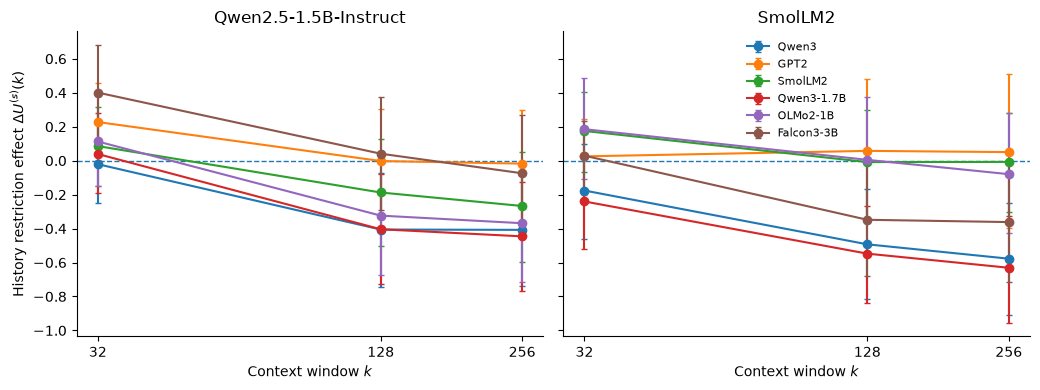

saved: ../figures/context_intervention_modern_scorers.pdf
saved: ../figures/context_intervention_modern_scorers.png


In [12]:
plot_df = summary[
    summary["metric"].isin(["delta_U_32","delta_U_128","delta_U_256"])
].copy()
plot_df["k"] = plot_df["metric"].map({
    "delta_U_32":32,
    "delta_U_128":128,
    "delta_U_256":256,
})

generators = list(pairs["generator"].drop_duplicates())
fig, axes = plt.subplots(1, len(generators), figsize=(10.5, 4.0), sharey=True)
if len(generators) == 1:
    axes = [axes]

for ax, gen in zip(axes, generators):
    zg = plot_df[plot_df["generator"] == gen]
    for scorer in ALL_SCORER_ORDER:
        z = zg[zg["scorer"] == scorer].sort_values("k")
        if len(z) == 0:
            continue
        y = z["mean"].to_numpy()
        err = np.vstack([
            y - z["ci_low"].to_numpy(),
            z["ci_high"].to_numpy() - y,
        ])
        ax.errorbar(
            z["k"], y, yerr=err,
            marker="o", linewidth=1.5, capsize=2,
            label=scorer,
        )

    ax.axhline(0, linestyle="--", linewidth=1)
    ax.set_xscale("log", base=2)
    ax.set_xticks([32,128,256])
    ax.set_xticklabels(["32","128","256"])
    ax.set_xlabel("Context window $k$")
    ax.set_title(gen)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylabel(r"History restriction effect $\Delta U^{(s)}(k)$")
axes[-1].legend(frameon=False, fontsize=8)
fig.tight_layout()

FIG_PDF = FIGURES / "context_intervention_modern_scorers.pdf"
FIG_PNG = FIGURES / "context_intervention_modern_scorers.png"
fig.savefig(FIG_PDF, bbox_inches="tight")
fig.savefig(FIG_PNG, dpi=250, bbox_inches="tight")
plt.show()

print("saved:", FIG_PDF)
print("saved:", FIG_PNG)


## 11. Save frozen outputs


In [13]:
SUMMARY_PATH = RESULTS / "context_intervention_modern_scorer_summary.csv"
COMMON_PATH = RESULTS / "context_intervention_modern_scorer_common_eligible.csv"
CRITERION_PATH = RESULTS / "context_intervention_modern_scorer_criterion.csv"

summary.to_csv(SUMMARY_PATH, index=False)
common_summary.to_csv(COMMON_PATH, index=False)
criterion_df.to_csv(CRITERION_PATH, index=False)

print("saved:")
for p in [
    NEW_ALL_PATH,
    SUMMARY_PATH,
    COMMON_PATH,
    CRITERION_PATH,
    FIG_PDF,
    FIG_PNG,
]:
    print(" ", p)


saved:
  ../results/context_intervention_modern_scorer_scores.parquet
  ../results/context_intervention_modern_scorer_summary.csv
  ../results/context_intervention_modern_scorer_common_eligible.csv
  ../results/context_intervention_modern_scorer_criterion.csv
  ../figures/context_intervention_modern_scorers.pdf
  ../figures/context_intervention_modern_scorers.png


## 12. Interpretation gate

### Outcome A — broad modern-scorer replication

If Qwen3-1.7B and at least one independent modern scorer recover clearly
negative long-range effects for both generators:

> The history-access intervention is not specific to the original Qwen3-0.6B
> observer. Its population-level long-range effect is recoverable by multiple
> contemporary pretrained observation models, although effect magnitude remains
> scorer-relative.

Do **not** say that all sufficiently large models recover the trace unless a
formal capability trend is separately established.

### Outcome B — only Qwen-family models replicate

> The intervention effect is robust to scorer scale within Qwen3 but does not
> yet generalize across scorer families. A family-specific observation affinity
> remains viable.

This would make aligned-target Notebook 25b worthwhile.

### Outcome C — independent modern models are negative but imprecise

> The intervention is directionally concordant across contemporary scorers, but
> the present \(n=60/n=40\) experiment does not estimate all observation-model
> effects precisely.

This is stronger than Notebook 25, but still not "scorer-invariant."

### Outcome D — new scorers remain mixed/null

> Generator-history sensitivity is strongly observation-model dependent; the
> frozen Qwen3-0.6B scorer is unusually sensitive to the manipulation.

At that point run the aligned-target control once, then stop this branch rather
than searching further scorer/model transformations.
